'''
Random forrest

#TODO write more :)


'''

In [43]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier


class DataLoader:
    '''
    Dataloader to use before I get the real one
    '''

    def __init__(self):
        '''
        Initialize the class function
        '''

    def get_data(self):
        '''
        :param Input: Datalocation
        :print: Optional datainfo.
        :return: Output: Dataframe
        '''
        # df = pd.DataFrame(pd.read_excel("gallstone_fully_cleaned_for_rf.xlsx"))
        # df = pd.DataFrame(pd.read_excel("dataset-uci1.xlsx"))
        df = pd.DataFrame(pd.read_csv("dataset_uci_testing_set.csv"))
        # for col in df.columns:
        #     if df[col].isin([0, 1]).all():
        #         df[col] = df[col].astype(bool)
        # print("1")

        # print(df.head())
        # print(list(df)) # print the headers
        #print(df.describe().T)
        # idx = df["Obesity (%)"].idxmax()
        # print(df.loc[idx])
        
        # df.info()
       
        #print(df.head()) # print the first 5 rows of the dataframe

        return df
        
      
# Local_df = DataLoader.get_data(self=DataLoader)


Data split
OOB accuracy:  0.771
Test accuracy: 0.776
ROC AUC Score: 0.871

Classification report
              precision    recall  f1-score   support

           0       0.76      0.83      0.79        30
           1       0.80      0.71      0.75        28

    accuracy                           0.78        58
   macro avg       0.78      0.77      0.77        58
weighted avg       0.78      0.78      0.77        58

Train accuracy: 0.883
Test accuracy: 0.776
Overfit gap: 0.107


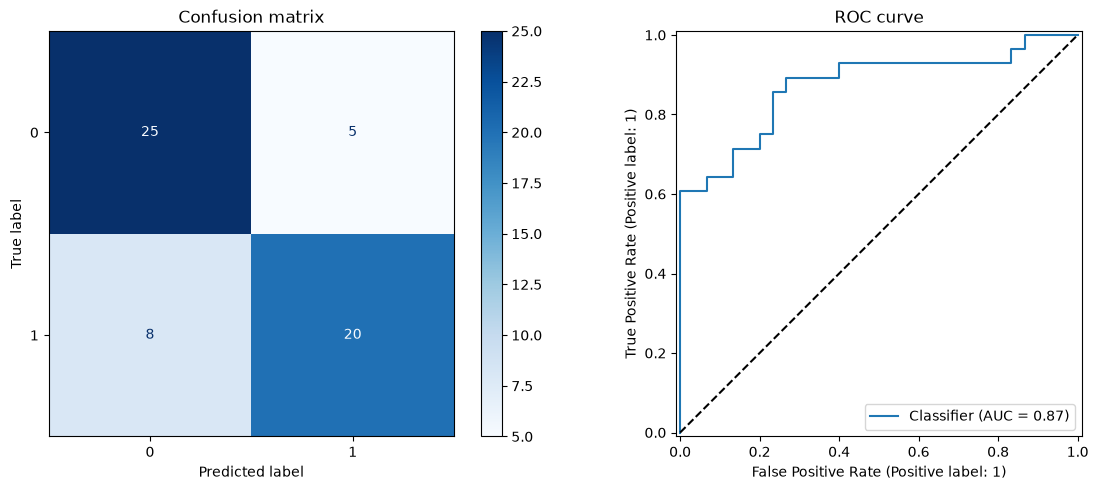

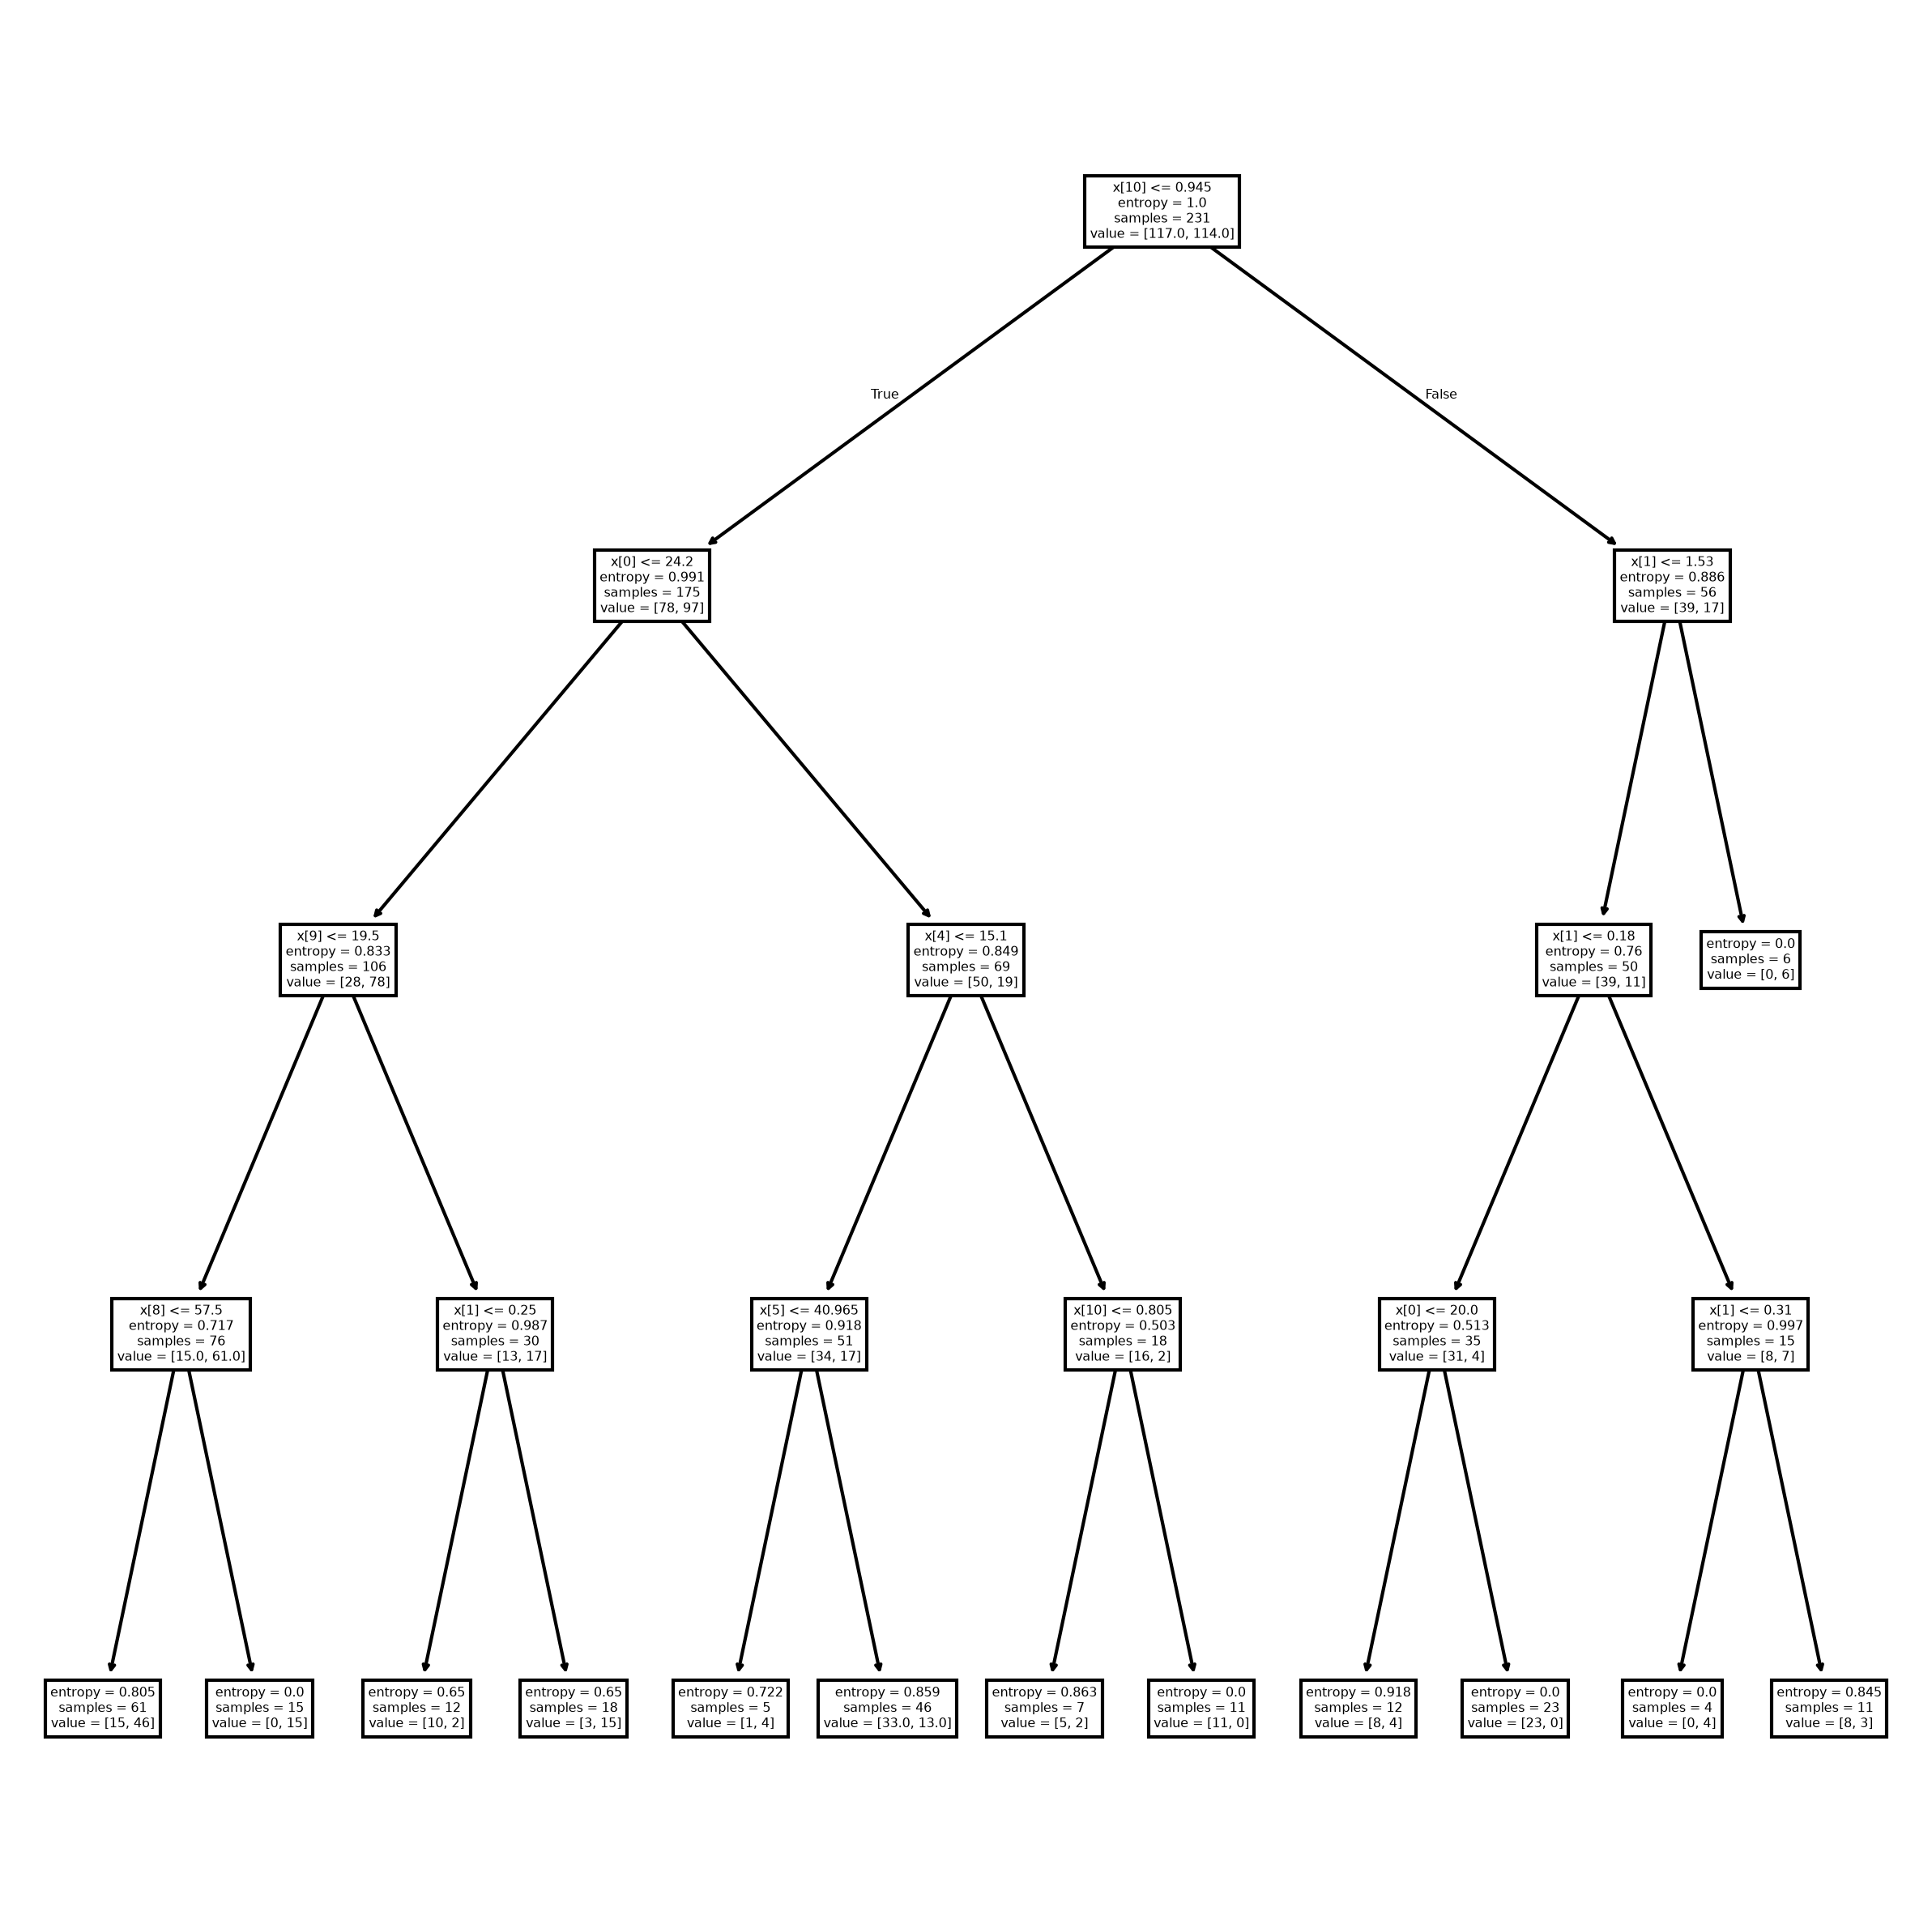

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier
from sklearn import tree

class RandomForrest:
    '''Random Forest model for predicting gallstone status.'''

    def __init__(self, random_state = 77, test_size = 0.2):
        """
        # Init the class Randomforrest:

        Args
        -----
            random_state : random seed.
            df : Datainput.
            test_size : The size for how much should be kept as training.

        Attributes
        ----------
            model : Initiate the model (empty)
          
        Definition
        ----------
            split_data() : Initiate splitting of the data
        
        """
        self.random_state = random_state
        self.df = DataLoader().get_data()
        self.model = None
        self.test_size = test_size
        self.features = self.split_data()

    def split_data(self):
        target = "Gallstone Status"
        FEATURES_FIRST_DRAFT = [
                            "Age",
                            "Body Mass Index (BMI)",
                            "Total Body Fat Ratio (TBFR) (%)",
                            "Visceral Fat Rating (VFR)",
                            "Visceral Fat Area (VFA)",
                            "Glucose",
                            "Total Cholesterol (TC)",
                            "Low Density Lipoprotein (LDL)",
                            "High Density Lipoprotein (HDL)",
                            "Triglyceride",
                            "Vitamin D"
                        ]
        PREFERED_FEATURES_13 = [
                            'Vitamin D',
                            'C-Reactive Protein (CRP)',
                            'Total Body Fat Ratio (TBFR) (%)',
                            'Bone Mass (BM)',
                            'Hemoglobin (HGB)',
                            "Extracellular Fluid/Total Body Water (ECF/TBW)",
                            'Hyperlipidemia',
                            'Gender',
                            'High Density Lipoprotein (HDL)',
                            'Aspartat Aminotransferaz (AST)',
                            'Creatinine',
                            'Alkaline Phosphatase (ALP)',
                            'Diabetes Mellitus (DM)'
                        ]

        FEATURES = PREFERED_FEATURES_13
        # X = self.df.drop(columns=[target])
        # X = self.df[FEATURES_FIRST_DRAFT]
        X = self.df[PREFERED_FEATURES_13]
        y = self.df[target]
        print("Data split")
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
                    X, y, test_size = self.test_size, stratify = y, random_state = self.random_state)
        
        # stratify = y ensure equal distribution of target = "Gallstone Status" with train and test data.
        
        return FEATURES

    def train_model(self, **params):
        defaults = dict(n_estimators = 1000, max_features = 0.3, max_depth = 4,
                        min_samples_leaf = 3, criterion = "entropy",
                        oob_score = True, n_jobs = -1, random_state  = self.random_state,
                        bootstrap = True, warm_start = False)
        defaults.update(params) # Update defaults with new parameters
        
        self.model = RandomForestClassifier(**defaults)
        self.model.fit(self.X_train, self.y_train)
        
        # Get predicted class probabilities for the test set
        y_pred_prob = self.model.predict_proba(self.X_test)[:, 1]
        predictions = self.model.predict(self.X_test)
        train_score = self.model.score(self.X_train, self.y_train)
        test_score = self.model.score(self.X_test, self.y_test)

        print(f"OOB accuracy:  {self.model.oob_score_:.3f}")
        print(f"Test accuracy: {accuracy_score(self.y_test, predictions):.3f}")
        print(f"ROC AUC Score: {roc_auc_score(self.y_test, y_pred_prob):.3f}\n")
        print("Classification report")
        print(classification_report(self.y_test, predictions))
        
        print(f"Train accuracy: {train_score:.3f}")
        print(f"Test accuracy: {test_score:.3f}")
        print(f"Overfit gap: {train_score - test_score:.3f}")

        '''
        https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html
        '''
        cm = confusion_matrix(self.y_test, predictions, labels=self.model.classes_)
        

        '''
        https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html
        https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html
        https://www.geeksforgeeks.org/machine-learning/calculate-roc-auc-for-classification-algorithm-such-as-random-forest/
        '''

        # plot
        fig, ax =  plt.subplots(1, 2, figsize=(12, 5))
        ConfusionMatrixDisplay.from_predictions(self.y_test, predictions, ax = ax[0], cmap = "Blues")
        ax[0].set_title("Confusion matrix")
        RocCurveDisplay.from_predictions(self.y_test, y_pred_prob, ax = ax[1])
        ax[1].plot([0, 1], [0, 1], "k--")
        ax[1].set_title("ROC curve")  
        plt.tight_layout()
        plt.show()
        defaults_clf = dict(max_features = 0.3, max_depth = 4,
                        min_samples_leaf = 3, criterion = "entropy",
                        random_state  = self.random_state,
                        
                        )
        # Not a random forrest, but a single tree
        # Visualizing the decision
        clf = tree.DecisionTreeClassifier(**defaults_clf)
        clf.fit(self.X_train, self.y_train)
        plt.figure(figsize = (10, 10), dpi = 300)
        tree.plot_tree(clf)
        plt.show()

        return self.model


# Only used for making the cell and tuning parameters, obsolete, but keeping around
if __name__ == "__main__": # ONly run when the code is run directly.
    rf = RandomForrest(random_state = 14, test_size = 0.2) # Initiate RandomForrest with test_size = 0.3
    rf.train_model() # Calling train_model with params
    # rf.train_model(n_estimators = 500, max_features = "sqrt", max_depth = None,
                # min_samples_leaf = 2, criterion = "entropy", random_state  = 14,
                # min_samples_split = 5
                # ) # Trying different params to see if it improves accuracy



If the curve stays above the diagonal line, generally means the model ranks positive cases better than random.
The closer to the top left corner, the better the trade of between finding positives and avoiding false positives.


38 were actually False and predicted False.
10 were actually False but predicted True — false positives.
12 were actually True but predicted False — false negatives.
36 were actually True and predicted True.

In [45]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

class RandomForrestValidation:
    """
    Uses a unseen dataset to validate/test the trained model
    
    """
    def __init__(self, target = "None", features = "None"):
        """
        Load validation dataset
        """
        self.df_unseen = pd.read_csv("dataset_uci_validation_set.csv")
        self.target = target
        self.features = features

    def evaluate(self, model):
        """
        Evaluate the trained model against unseen data
        """
        self.X_new = self.df_unseen[self.features]
        pred = model.predict(self.X_new)
        y_pred_prob = model.predict_proba(self.X_new)[:, 1]

        out = self.X_new[self.features].copy()
        out["P(class 1)"] = y_pred_prob.round(2)
        out["Predicted"]  = pred
        out["Actual"] = self.df_unseen[self.target].to_numpy()
        out["Correct"] = out["Predicted"] == out["Actual"]
        self.y_new = self.df_unseen[self.target]

        # plot
        print(f"Unseen accuracy: {accuracy_score(self.y_new, pred):.3f}  (n = {len(self.y_new)})")
        print(f"Unseen ROC-AUC:  {roc_auc_score(self.y_new, y_pred_prob):.3f}")
        print(classification_report(self.y_new, pred))
        print(f"ROC AUC Score: {roc_auc_score(self.y_new, y_pred_prob):.3f}")
        fig, ax =  plt.subplots(1, 2, figsize=(12, 5))
        ConfusionMatrixDisplay.from_predictions(self.y_new, pred, ax = ax[0], cmap = "Blues")
        ax[0].set_title("Confusion matrix (unseen data)")
        RocCurveDisplay.from_predictions(self.y_new, y_pred_prob, ax = ax[1])
        ax[1].plot([0, 1], [0, 1], "k--")
        ax[1].set_title("ROC curve (unseen data)")
        plt.tight_layout()
        plt.show()

        display(out.head(30))


# validation = RandomForrestValidation()
# validation.evaluate(rf.model)

Unseen accuracy: 0.833  (n = 30)
Unseen ROC-AUC:  0.888
              precision    recall  f1-score   support

           0       0.76      0.93      0.84        14
           1       0.92      0.75      0.83        16

    accuracy                           0.83        30
   macro avg       0.84      0.84      0.83        30
weighted avg       0.85      0.83      0.83        30

ROC AUC Score: 0.888


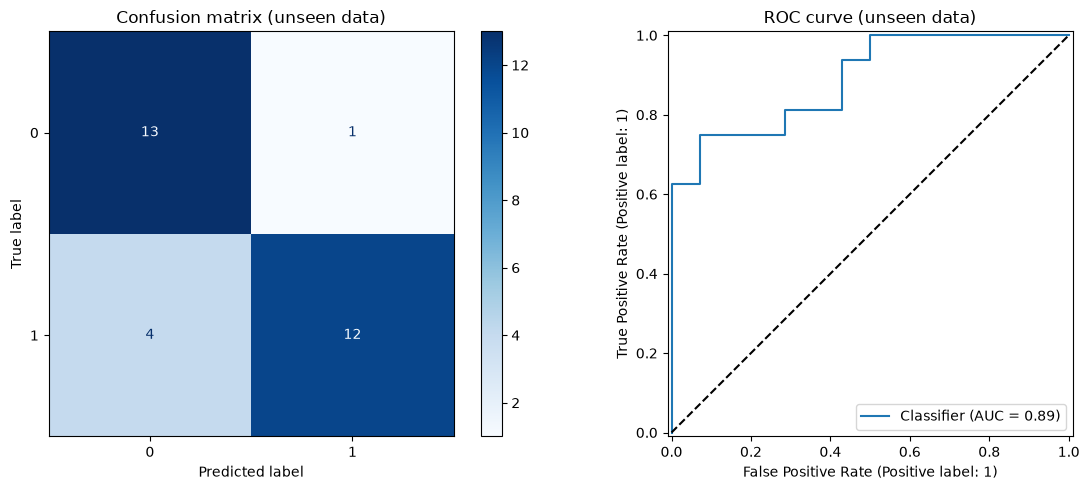

,Vitamin D,C-Reactive Protein (CRP),Total Body Fat Ratio (TBFR) (%),Bone Mass (BM),Hemoglobin (HGB),Extracellular Fluid/Total Body Water (ECF/TBW),Hyperlipidemia,Gender,High Density Lipoprotein (HDL),Aspartat Aminotransferaz (AST),Creatinine,Alkaline Phosphatase (ALP),Diabetes Mellitus (DM),P(class 1),Predicted,Actual,Correct
0,8.300000,6.20,24.66,3.3,16.5,42.01,0,0,55.0,28.0,0.98,90.0,0,0.75,1,1,True
1,11.200000,8.10,22.17,2.3,16.5,40.33,0,0,48.0,21.0,0.85,66.0,0,0.80,1,1,True
2,51.400000,0.16,28.80,3.1,16.4,44.00,0,0,36.0,15.0,0.89,24.0,1,0.28,0,0,True
3,40.000000,0.00,30.20,3.9,16.6,41.00,0,0,42.0,16.0,0.86,66.0,1,0.28,0,0,True
4,18.700000,43.40,18.50,3.3,14.8,40.00,0,0,31.0,17.0,0.92,78.0,0,0.74,1,1,True
5,20.012500,0.04,19.20,2.8,14.5,44.00,0,0,58.0,18.0,0.86,63.0,1,0.43,0,0,True
6,18.000000,2.40,36.02,3.2,12.4,34.31,0,1,57.0,21.0,0.79,73.0,0,0.85,1,1,True
7,35.400000,1.25,19.10,2.8,13.9,43.00,0,0,32.0,14.0,0.73,86.0,1,0.57,1,1,True
8,25.000000,3.30,31.20,2.0,13.5,47.00,0,1,77.0,29.0,0.57,49.0,0,0.51,1,1,True
9,53.100000,0.47,40.80,2.6,14.8,47.00,1,1,49.0,13.0,0.59,57.0,1,0.36,0,1,False


In [46]:
TARGET = "Gallstone Status"
# FEATURES = [
    #     'Vitamin D', 'C-Reactive Protein (CRP)', 'Total Body Fat Ratio (TBFR) (%)',
    #     'Bone Mass (BM)', 'Hemoglobin (HGB)', 'Extracellular Fluid/Total Body Water (ECF/TBW)',
    #     'Hyperlipidemia', 'Gender', 'High Density Lipoprotein (HDL)',
    #     'Aspartat Aminotransferaz (AST)', 'Creatinine', 'Alkaline Phosphatase (ALP)',
    #     'Diabetes Mellitus (DM)'
    # ]   # must be exactly the features the model was trained on

validation = RandomForrestValidation(target = TARGET, features = rf.features)
validation.evaluate(rf.model)

PREFERED_FEATURES = [
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    'Extracellular Fluid/Total Body Water (ECF/TBW)',
    'Hyperlipidemia'
]
 
PREFERED_FEATURES_13=[
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    "Extracellular Fluid/Total Body Water (ECF/TBW)",
    'Hyperlipidemia',
    'Gender',
    'High Density Lipoprotein (HDL)',
    'Aspartat Aminotransferaz (AST)',
    'Creatinine',
    'Alkaline Phosphatase (ALP)',
    'Diabetes Mellitus (DM)'
]

In [47]:
# from sklearn.model_selection import GridSearchCV
# from sklearn.ensemble import RandomForestClassifier

# # param_grid = {
# #     'n_estimators': [100, 200],
# #     'max_depth': [None, 10, 20],
# #     'min_samples_split': [2, 5],
# #     'min_samples_leaf': [1, 2],
# #     'bootstrap': [True, False]
# # }

# param_grid = {
#     "n_estimators": [100, 500, 1000], 
# #     "max_features": ["sqrt", "log2", None, 0.3],
#     "max_depth": [None, 4, 6],
#     "min_samples_split": [2, 5],
#     "min_samples_leaf": [2, 3 ,5], 
# #     "criterion": ["gini", "entropy", "log_loss"]
# }

# grid_search = GridSearchCV(RandomForestClassifier(), param_grid=param_grid, cv = 5, verbose = 2)
# grid_search.fit(rf.X_train, rf.y_train)

# print("Best Parameters:", grid_search.best_params_)
# print("Best Estimator:", grid_search.best_estimator_)

# """
# https://www.geeksforgeeks.org/machine-learning/random-forest-hyperparameter-tuning-in-python/
# """

# """
# Alternative
# https://medium.com/data-science/hyperparameter-tuning-the-random-forest-in-python-using-scikit-learn-28d2aa77dd74
# """

Test ran
Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best Estimator: RandomForestClassifier(criterion='entropy', max_depth=5, min_samples_leaf=2)

In [48]:
"""
Dummy to test whether the automatic parameter tuning had any positive effect.
Tuning ran for 1 hour,did not have any effect :(
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier

class RandomForrest:
    '''Random Forest model for predicting gallstone status.'''

    def __init__(self, random_state = 77, test_size = 0.2):
        self.random_state = random_state
        self.df = DataLoader().get_data()
        self.model = None
        self.test_size = test_size
        self.split_data()

    def split_data(self):
        target = "Gallstone Status"
        selected_features = [
                            "Age",
                            "Body Mass Index (BMI)",
                            "Total Body Fat Ratio (TBFR) (%)",
                            "Visceral Fat Rating (VFR)",
                            "Visceral Fat Area (VFA)",
                            "Glucose",
                            "Total Cholesterol (TC)",
                            "Low Density Lipoprotein (LDL)",
                            "High Density Lipoprotein (HDL)",
                            "Triglyceride",
                            "Vitamin D"
                        ]
        X = self.df.drop(columns=[target])
        # X = self.df[selected_features]
        y = self.df[target]
        print("Data split")
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
                    X, y, test_size = self.test_size, stratify = y, random_state = self.random_state)
        
        # stratify = y ensure equal distribution of target = "Gallstone Status" with train and test data.

# 1 hour run        
# Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
# Best Estimator: RandomForestClassifier(criterion='entropy', max_depth=5, min_samples_leaf=2)

# Short run
# Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 500}
# Best Estimator: RandomForestClassifier(min_samples_leaf=2, min_samples_split=5,

    def train_model(self, **params):
        defaults = dict(n_estimators = 500, max_features = "sqrt", max_depth = None,
                        min_samples_leaf = 2, criterion = "entropy",
                        oob_score = True, n_jobs = -1, random_state  = self.random_state,
                        min_samples_split = 5)
        defaults.update(params) # Update defaults with new parameters
        
        self.model = RandomForestClassifier(**defaults)
        self.model.fit(self.X_train, self.y_train)

        predictions = self.model.predict(self.X_test)
        #print(f"OOB accuracy:  {self.model.oob_score_:.3f}")
        print(f"Test accuracy: {accuracy_score(self.y_test, predictions):.3f}")
        print("Confusion matrix")
        print(confusion_matrix(self.y_test, predictions))
        print("Classification report")
        print(classification_report(self.y_test, predictions))
        train_score = self.model.score(self.X_train, self.y_train)
        test_score = self.model.score(self.X_test, self.y_test)
        print(f"Train accuracy: {train_score:.3f}")
        print(f"Test accuracy: {test_score:.3f}")
        print(f"Overfit gap: {train_score - test_score:.3f}")
        return self.model

if __name__ == "__main__": # ONly run when the code is run directly.
    rf = RandomForrest(random_state = 14, test_size=0.2) # Initiate RandomForrest with test_size=0.3
    rf.train_model(min_samples_leaf=2, max_depth=None, n_estimators = 500) # Calling train_model with params
    #rf.train_model(min_samples_leaf=3, max_depth=4, n_estimators = 1000, warm_start = True) # Trying different params to see if it improves accuracy



Data split
Test accuracy: 0.793
Confusion matrix
[[26  4]
 [ 8 20]]
Classification report
              precision    recall  f1-score   support

           0       0.76      0.87      0.81        30
           1       0.83      0.71      0.77        28

    accuracy                           0.79        58
   macro avg       0.80      0.79      0.79        58
weighted avg       0.80      0.79      0.79        58

Train accuracy: 1.000
Test accuracy: 0.793
Overfit gap: 0.207


Forklar hvorfor feature select ikke gir et bedre resultat.

In [49]:
rf = RandomForrest(random_state = 14, test_size = 0.2) # Initiate RandomForrest with test_size = 0.3
rf.train_model() # Calling train_model with params
# rf.train_model(n_estimators = 500, max_features = "sqrt", max_depth = None,
            # min_samples_leaf = 2, criterion = "entropy", random_state  = 14,
            # min_samples_split = 5
            # ) # Trying different params to see if it improves accuracy

Data split
Test accuracy: 0.793
Confusion matrix
[[26  4]
 [ 8 20]]
Classification report
              precision    recall  f1-score   support

           0       0.76      0.87      0.81        30
           1       0.83      0.71      0.77        28

    accuracy                           0.79        58
   macro avg       0.80      0.79      0.79        58
weighted avg       0.80      0.79      0.79        58

Train accuracy: 1.000
Test accuracy: 0.793
Overfit gap: 0.207


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",14
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashi

In [50]:
# TARGET = "Gallstone Status"
# FEATURES = [
#         'Vitamin D', 'C-Reactive Protein (CRP)', 'Total Body Fat Ratio (TBFR) (%)',
#         'Bone Mass (BM)', 'Hemoglobin (HGB)', 'Extracellular Fluid/Total Body Water (ECF/TBW)',
#         'Hyperlipidemia', 'Gender', 'High Density Lipoprotein (HDL)',
#         'Aspartat Aminotransferaz (AST)', 'Creatinine', 'Alkaline Phosphatase (ALP)',
#         'Diabetes Mellitus (DM)'
#     ]   # must be exactly the features the model was trained on

# validation = RandomForrestValidation(target = TARGET, features = FEATURES)
# validation.evaluate(rf.model)